# Retrieval experiments and article figures
This notebook reproduces the retrieval experiments and generates the corresponding figures used in the article.

The three experiments assess:
1. retrieval from a perfect cue at network load $ac = 0.7$;
2. retrieval from a perfect cue at network load $ac = 1.0$;
3. retrieval from an incomplete cue with 2 inactive blocks at $ac = 0.5$.

All random-number generators are explicitly seeded.

Run the notebook from top to bottom to reproduce the pattern set, simulations, and figures.

## Environment and imports
The setup below locates the project root whether the notebook is started from the repository root or from its notebooks/ directory.

Generated patterns and figures are written to dedicated output directories.

In [4]:
from pathlib import Path
import sys
import numpy as np
import torch


def find_project_root(start: Path) -> Path:
    """Return the nearest parent directory containing the src package."""
    start = start.resolve()

    for candidate in (start, *start.parents):
        if (candidate / "src").is_dir():
            return candidate

    raise FileNotFoundError(
        "Could not locate the project root containing the 'src' directory."
    )


PROJECT_ROOT = find_project_root(Path.cwd())

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.block import Block
from src.patterns import random_patterns, remove_bits
from src.plotting import complete_plot_retrieval, plot_retrieval_only

DATA_DIR = PROJECT_ROOT / "patterns"
FIGURE_DIR = PROJECT_ROOT / "figures"
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")

Project root: /media/neurolab/Dati/associative_memory_HH


## Reproducibility and simulation parameters
The network contains $N = 200$ blocks.

Each stored pattern activates a fraction $f=0.1$ of the blocks.

The load $ac = P/N$ determines the number $P$ of stored patterns.
Time is measured in milliseconds and membrane potentials in millivolts. The numerical integration step is $0.025,\mathrm{ms}$, within the range used for conductance-based neuronal simulations.

In [5]:
# Reproducibility
PATTERN_SEED = 42
CORRUPTION_SEED = 43
SIMULATION_SEED = 44

# Simulation interval (ms)
T_START = 0.0
T_END = 200.0
DT = 0.025

# External-current interval (ms) and amplitude
CURRENT_START = 0.0
CURRENT_END = 2.0
CURRENT_VALUE = 10.0

# Network and pattern parameters
N_BLOCKS = 200
ACTIVITY_FRACTION = 0.1
N_ACTIVE_BLOCKS = int(ACTIVITY_FRACTION * N_BLOCKS)
TARGET_PATTERN = 23

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float32

pattern_rng = np.random.default_rng(PATTERN_SEED)
corruption_rng = np.random.default_rng(CORRUPTION_SEED)

print(f"Device: {device}")
print(f"Network: {N_BLOCKS} blocks ({4 * N_BLOCKS} neurons)")
print(f"Active blocks per pattern: {N_ACTIVE_BLOCKS}")

Device: cuda
Network: 200 blocks (800 neurons)
Active blocks per pattern: 20


## Stored patterns
A single deterministic set of $N$ patterns is generated. Each experiment uses the required prefix of this common set, ensuring that differences between experiments arise from network load or cue degradation rather than unrelated pattern realizations.

In [6]:
all_patterns = random_patterns(
    n_patterns=N_BLOCKS,
    n_blocks=N_BLOCKS,
    active_blocks=N_ACTIVE_BLOCKS,
    rng=pattern_rng,
)

if not 0 <= TARGET_PATTERN < len(all_patterns):
    raise IndexError("TARGET_PATTERN is outside the generated pattern set.")

patterns_path = DATA_DIR / "retrieval_patterns.csv"
np.savetxt(patterns_path, all_patterns, delimiter=",", fmt="%d")

print(f"Pattern matrix: {all_patterns.shape}")
print(f"Saved to: {patterns_path}")

Pattern matrix: (200, 200)
Saved to: /media/neurolab/Dati/associative_memory_HH/patterns/retrieval_patterns.csv


## Experiment runner
The helper function centralizes network construction, synaptic parameters, simulation, and overlap calculation. A separate simulation seed is supplied for each experiment so that results remain reproducible even when cells are executed independently.

In [7]:
def run_retrieval_experiment(
    stored_patterns: np.ndarray,
    input_pattern: np.ndarray,
    *,
    simulation_seed: int,
):
    torch.manual_seed(simulation_seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(simulation_seed)

    network = Block(
        n_blocks=N_BLOCKS,
        input_pattern=input_pattern,
        device=device,
        dtype=dtype,
    )

    network.set_stored_patterns(stored_patterns)

    network.update_chemical_connections(
        rsa_rsa=0.3 / N_ACTIVE_BLOCKS,
        fs_rsa=0.12 * N_ACTIVE_BLOCKS,
        fs_fs=0.03 / N_ACTIVE_BLOCKS,
    )

    solution_t, solution_y = network.solution(
        T_START,
        T_END,
        DT,
        [CURRENT_START, CURRENT_END],
        [CURRENT_VALUE],
    )

    initial_overlap, time_overlap = network.calculate_overlap(solution_t)

    return network, solution_t, solution_y, initial_overlap, time_overlap

## Perfect cue, $ac = 0.7$
The first experiment stores $P=0.7N$ patterns. The cue is identical to stored pattern $\mu=23$, i.e. $\zeta=\mu$.

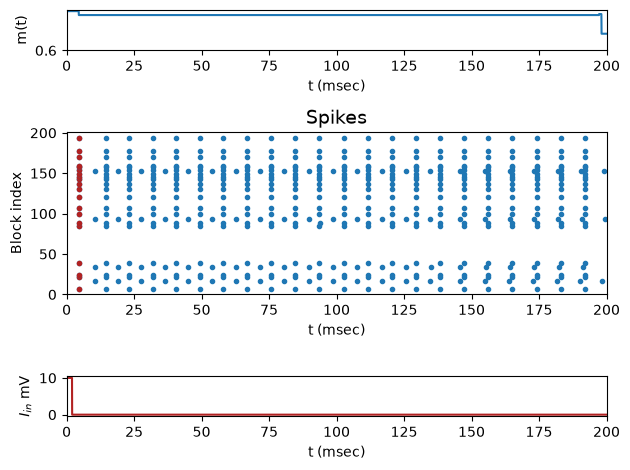

Stored patterns: 140
Initial target overlap: 1.000
Maximum target overlap: 1.000


In [ ]:
load_07 = 0.7
patterns_07 = all_patterns[: int(load_07 * N_BLOCKS)]
input_07 = patterns_07[TARGET_PATTERN].copy()

network_07, sol_t_07, sol_y_07, m_i_07, m_t_07 = run_retrieval_experiment(
    patterns_07,
    input_07,
    simulation_seed=SIMULATION_SEED,
)

complete_plot_retrieval(
    network_07,
    sol_t_07,
    m_t_07,
    TARGET_PATTERN,
    differents=[],
    name=FIGURE_DIR / "perfect_retrieval_ac_07.png",
)

print(f"Stored patterns: {len(patterns_07)}")
print(f"Initial target overlap: {float(m_i_07[TARGET_PATTERN]):.3f}")
print(f"Maximum target overlap: {float(m_t_07[TARGET_PATTERN].max()):.3f}")


## Perfect cue, $ac = 1.0$
The second experiment stores $P=N$ patterns while retaining the same perfect cue and connectivity parameters.

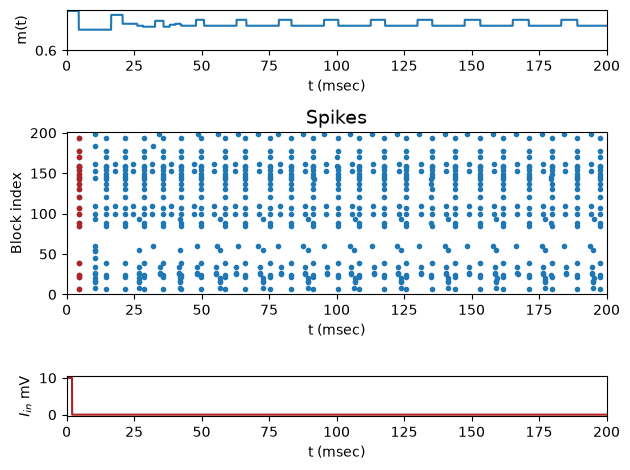

Stored patterns: 200
Initial target overlap: 1.000
Maximum target overlap: 1.000


In [ ]:
load_10 = 1.0
patterns_10 = all_patterns[: int(load_10 * N_BLOCKS)]
input_10 = patterns_10[TARGET_PATTERN].copy()

network_10, sol_t_10, sol_y_10, m_i_10, m_t_10 = run_retrieval_experiment(
    patterns_10,
    input_10,
    simulation_seed=SIMULATION_SEED + 1,
)

complete_plot_retrieval(
    network_10,
    sol_t_10,
    m_t_10,
    TARGET_PATTERN,
    differents=[],
    name=FIGURE_DIR / "perfect_retrieval_ac_10.png",
)

print(f"Stored patterns: {len(patterns_10)}")
print(f"Initial target overlap: {float(m_i_10[TARGET_PATTERN]):.3f}")
print(f"Maximum target overlap: {float(m_t_10[TARGET_PATTERN].max()):.3f}")

## Incomplete cue, $ac = 0.5$
The experiment stores $P=0.5N$ patterns. Two active blocks are removed from the cue before stimulation; their indices are highlighted in the output figure.

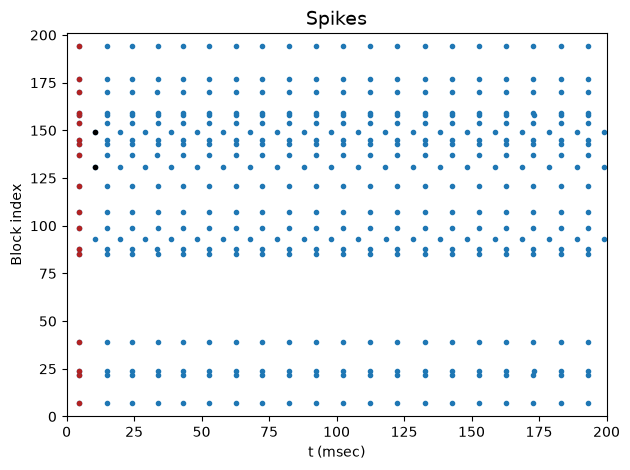

Stored patterns: 100
Removed blocks: [149, 131]
Initial target overlap: 0.980
Maximum target overlap: 0.990


In [10]:
load_05 = 0.5
patterns_05 = all_patterns[: int(load_05 * N_BLOCKS)]
perfect_input_05 = patterns_05[TARGET_PATTERN].copy()

imperfect_input_05, removed_blocks = remove_bits(
    perfect_input_05,
    2,
    rng=corruption_rng,
)

network_05, sol_t_05, sol_y_05, m_i_05, m_t_05 = run_retrieval_experiment(
    patterns_05,
    imperfect_input_05,
    simulation_seed=SIMULATION_SEED + 2,
)

plot_retrieval_only(
    network_05,
    sol_t_05,
    m_t_05,
    TARGET_PATTERN,
    differents=removed_blocks,
    name=FIGURE_DIR / "incomplete_retrieval_two_blocks.png",
)

print(f"Stored patterns: {len(patterns_05)}")
print(f"Removed blocks: {removed_blocks.tolist()}")
print(f"Initial target overlap: {float(m_i_05[TARGET_PATTERN]):.3f}")
print(f"Maximum target overlap: {float(m_t_05[TARGET_PATTERN].max()):.3f}")

## Software environment

In [ ]:
print(f"Python:     {sys.version.split()[0]}")
print(f"NumPy:      {np.__version__}")
print(f"PyTorch:    {torch.__version__}")
print(f"Device:     {device}")

Python:     3.12.3
NumPy:      2.5.0
PyTorch:    2.9.1+rocm6.4
Device:     cuda
